## 1. Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)


In [2]:
train = pd.read_csv('/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/train.csv')
test = pd.read_csv('/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/test.csv')
sample_sub = pd.read_csv('/kaggle/input/competitions/mlp-may-2026-kaggle-assignment-1/sample_submission.csv')

print('Train shape:', train.shape)
print('Test shape :', test.shape)
train.head()


Train shape: (40000, 12)
Test shape : (10000, 11)


,id,airline,flight,source,departure,stops,arrival,destination,class,duration,days_left,price
0,0,Vistara,UK-930,Mumbai,Early_Morning,one,Night,Chennai,Business,NaN,40.0,64173
1,1,Air_India,AI-539,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0,4357
2,2,SpiceJet,SG-8107,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0,3251
3,3,NaN,0.00E+00,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0,1776
4,4,Air_India,AI-569,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0,3584


## 2. Data Types


In [3]:
dtype_summary = pd.DataFrame({
    'dtype': train.dtypes.astype(str),
    'n_unique': train.nunique(),
    'sample_value': train.iloc[0]
})
dtype_summary


,dtype,n_unique,sample_value
id,int64,40000,0
airline,object,6,Vistara
flight,object,869,UK-930
source,object,6,Mumbai
departure,object,6,Early_Morning
stops,object,3,one
arrival,object,6,Night
destination,object,6,Chennai
class,object,2,Business
duration,float64,416,NaN


## 3. Descriptive Stats

In [4]:
numerical_cols = ['duration', 'days_left', 'price']

desc = train[numerical_cols].describe().T
desc['median'] = train[numerical_cols].median()
desc = desc[['min', 'max', 'mean', 'median', 'std', '25%', '50%', '75%']]
desc


,min,max,mean,median,std,25%,50%,75%
duration,0.83,47.08,12.004088,11.08,7.108063,6.67,11.08,15.92
days_left,1.00,49.00,26.197936,26.00,13.469232,15.00,26.00,38.00
price,1105.00,114704.00,20801.490250,7353.00,22729.148420,4687.00,7353.00,42521.00


## 4. Missing Value Analysis

In [5]:
missing = train.isna().sum()
missing_pct = (missing / len(train) * 100).round(2)
pd.DataFrame({'missing_count': missing, 'missing_%': missing_pct}).query('missing_count > 0')


,missing_count,missing_%
airline,4613,11.53
departure,4792,11.98
stops,2319,5.80
duration,3013,7.53
days_left,4438,11.10


In [6]:
# Airline code : airline name mapping, learned from rows where both are present
prefix_map = (
    train.assign(prefix=train['flight'].str.extract(r'^([A-Za-z0-9]+)-')[0])
         .dropna(subset=['airline'])
         .groupby('prefix')['airline']
         .agg(lambda s: s.mode()[0])
         .to_dict()
)
print(prefix_map)


{'AI': 'Air_India', 'G8': 'GO_FIRST', 'I5': 'AirAsia', 'SG': 'SpiceJet', 'UK': 'Vistara'}


In [7]:
def recover_airline(df):
    df = df.copy()
    prefix = df['flight'].str.extract(r'^([A-Za-z0-9]+)-')[0]
    recovered = np.where(df['flight'] == '0.00E+00', 'Indigo', prefix.map(prefix_map))
    df['airline'] = df['airline'].fillna(pd.Series(recovered, index=df.index))
    return df

train = recover_airline(train)
test = recover_airline(test)

print('Remaining missing airline values (train):', train['airline'].isna().sum())
print('Remaining missing airline values (test) :', test['airline'].isna().sum())


Remaining missing airline values (train): 86
Remaining missing airline values (test) : 9


In [8]:
# Remaining missing values:
#  - categorical columns (airline, departure, stops) -> impute with the mode (most frequent category)
#  - numerical columns (duration, days_left) -> impute with the median (robust to the right-skew we saw above)

cat_impute_cols = ['airline', 'departure', 'stops']
num_impute_cols = ['duration', 'days_left']

for c in cat_impute_cols:
    mode_val = train[c].mode()[0]
    train[c] = train[c].fillna(mode_val)
    test[c] = test[c].fillna(mode_val)

for c in num_impute_cols:
    median_val = train[c].median()
    train[c] = train[c].fillna(median_val)
    test[c] = test[c].fillna(median_val)

print('Missing values left in train:', train.isna().sum().sum())
print('Missing values left in test :', test.isna().sum().sum())


Missing values left in train: 0
Missing values left in test : 0


## 5. Duplicate Analysis and Treatment

In [9]:
# Duplicate Analysis and Treatment
feature_cols_for_dup_check = [c for c in train.columns if c != 'id']
n_dupes = train.duplicated(subset=feature_cols_for_dup_check).sum()
print(f'Number of duplicate rows (ignoring id): {n_dupes}')


Number of duplicate rows (ignoring id): 502


In [10]:
if n_dupes > 0:
    train = train.drop_duplicates(subset=feature_cols_for_dup_check).reset_index(drop=True)
    print('Duplicates dropped. New shape:', train.shape)
else:
    print('No duplicate rows found - nothing to drop.')


Duplicates dropped. New shape: (39498, 12)


## 6. Outlier Analysis and Treatment

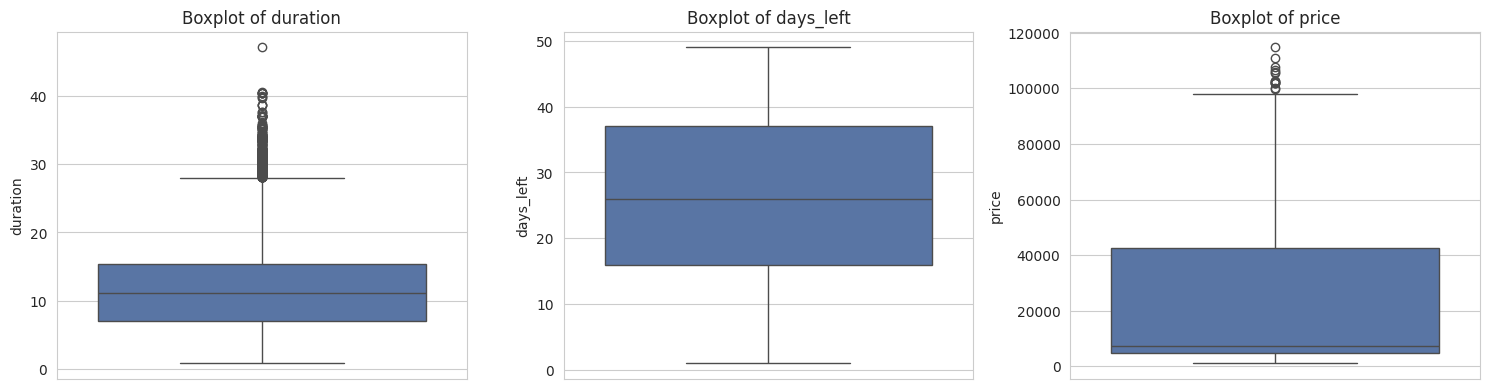

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['duration', 'days_left', 'price']):
    sns.boxplot(y=train[col], ax=ax, color='#4C72B0')
    ax.set_title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()


In [12]:
def iqr_outlier_count(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), lower, upper

for col in ['duration', 'days_left', 'price']:
    n_out, lo, hi = iqr_outlier_count(train[col])
    print(f'{col:10s}: {n_out:5d} IQR-outliers  (bounds: {lo:.2f} to {hi:.2f})')


duration  :   469 IQR-outliers  (bounds: -5.63 to 28.05)
days_left :     0 IQR-outliers  (bounds: -15.50 to 68.50)
price     :    14 IQR-outliers  (bounds: -51990.50 to 99125.50)


In [13]:
# quick sanity check: are the high-price "outliers" mostly Business class?
_, _, hi = iqr_outlier_count(train['price'])
pct_business = (train.loc[train['price'] > hi, 'class'] == 'Business').mean() * 100
print(f'{pct_business:.1f}% of price outliers are Business class tickets')


100.0% of price outliers are Business class tickets


## 7. EDA

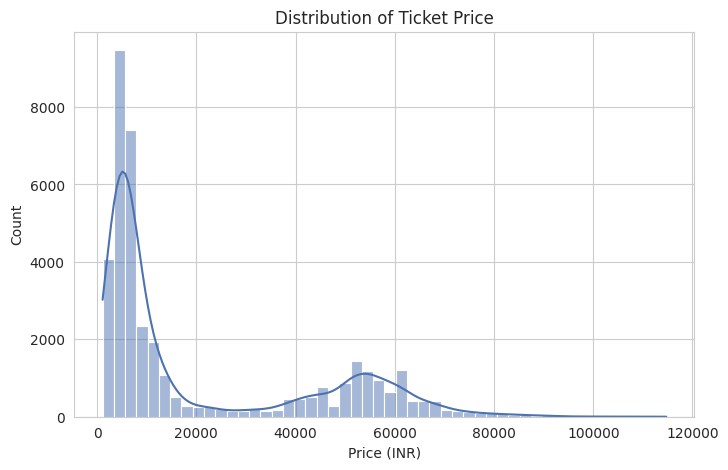

In [14]:
plt.figure(figsize=(8, 5))
sns.histplot(train['price'], bins=50, kde=True, color='#4C72B0')
plt.title('Distribution of Ticket Price')
plt.xlabel('Price (INR)')
plt.show()


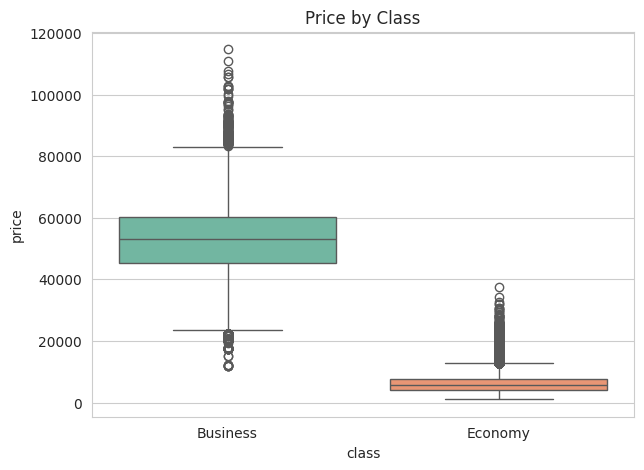

In [15]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=train, x='class', y='price', palette='Set2')
plt.title('Price by Class')
plt.show()


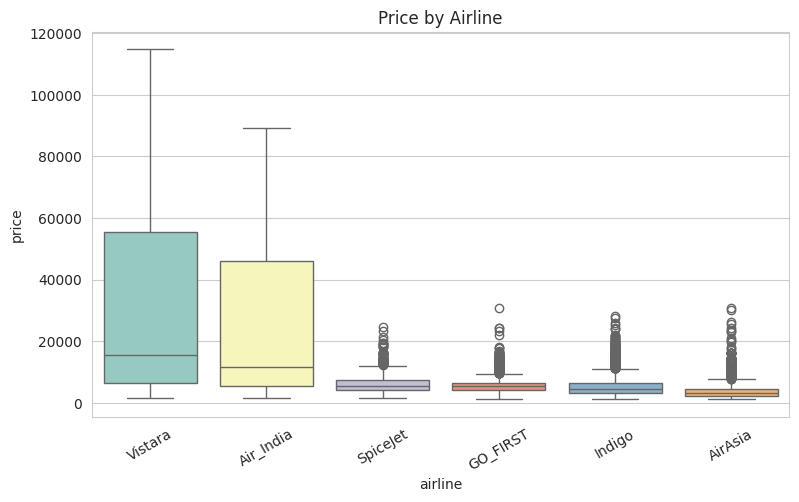

In [16]:
plt.figure(figsize=(9, 5))
order = train.groupby('airline')['price'].median().sort_values(ascending=False).index
sns.boxplot(data=train, x='airline', y='price', order=order, palette='Set3')
plt.title('Price by Airline')
plt.xticks(rotation=30)
plt.show()


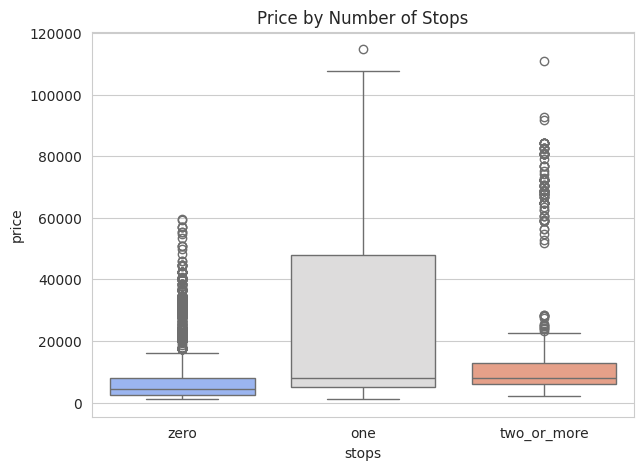

In [17]:
plt.figure(figsize=(7, 5))
stop_order = ['zero', 'one', 'two_or_more']
sns.boxplot(data=train, x='stops', y='price', order=stop_order, palette='coolwarm')
plt.title('Price by Number of Stops')
plt.show()


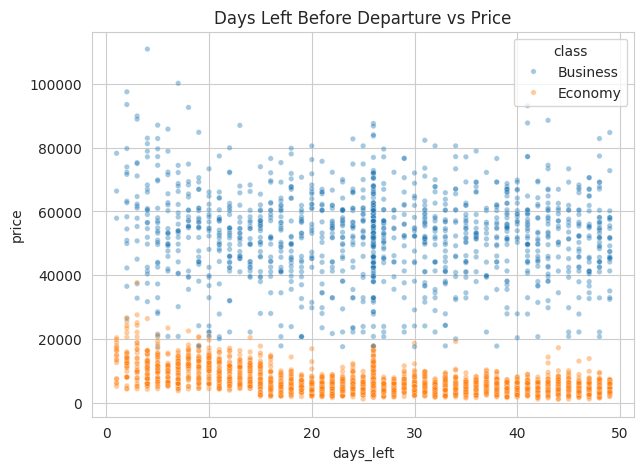

In [18]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=train.sample(4000, random_state=RANDOM_STATE),
                 x='days_left', y='price', hue='class', alpha=0.4, s=15)
plt.title('Days Left Before Departure vs Price')
plt.show()


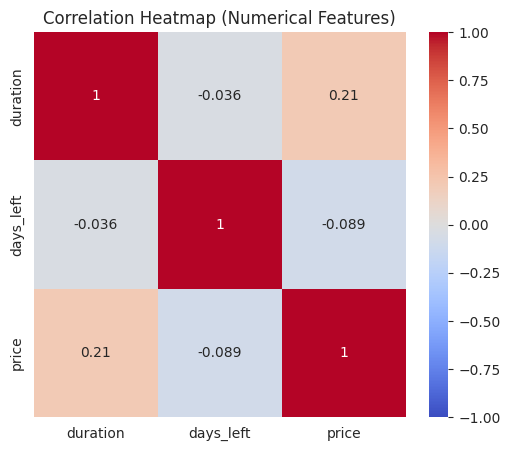

In [19]:
plt.figure(figsize=(6, 5))
corr = train[['duration', 'days_left', 'price']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Heatmap (Numerical Features)')
plt.show()


## 8. Feature Scaling and Encoding 
   

In [20]:
# Drop columns that are not useful as model features:
#  - 'id'      : just a row identifier
#  - 'flight'  : very high-cardinality (869 unique codes) flight number; its useful
#                signal (the airline) has already been extracted into 'airline'
drop_cols = ['id', 'flight']

categorical_features = ['airline', 'source', 'departure', 'stops', 'arrival', 'destination', 'class']
numerical_features = ['duration', 'days_left']

X = train.drop(columns=drop_cols + ['price'])
y = train['price']

X_test_final = test.drop(columns=[c for c in drop_cols if c in test.columns])

X.head()


,airline,source,departure,stops,arrival,destination,class,duration,days_left
0,Vistara,Mumbai,Early_Morning,one,Night,Chennai,Business,11.08,40.0
1,Air_India,Chennai,Evening,one,Morning,Mumbai,Economy,16.08,26.0
2,SpiceJet,Delhi,Early_Morning,zero,Morning,Chennai,Economy,2.92,25.0
3,Indigo,Hyderabad,Early_Morning,zero,Morning,Bangalore,Economy,1.50,22.0
4,Air_India,Chennai,Early_Morning,one,Morning,Bangalore,Economy,4.83,20.0


In [21]:
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', StandardScaler(), numerical_features),
    ]
)
preprocessor


ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 ['airline', 'source', 'departure', 'stops',
                                  'arrival', 'destination', 'class']),
                                ('num', StandardScaler(),
                                 ['duration', 'days_left'])])

## 9. Train/Test and Validation Splits

In [22]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print('Train size:', X_train.shape, ' Validation size:', X_val.shape)


Train size: (31598, 9)  Validation size: (7900, 9)


## 10. Model Training


In [23]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=RANDOM_STATE),
    'Lasso Regression': Lasso(random_state=RANDOM_STATE, max_iter=5000),
    'KNN Regressor': KNeighborsRegressor(n_neighbors=7),
    'Decision Tree': DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=15),
    'Random Forest': RandomForestRegressor(n_estimators=200, max_depth=18, random_state=RANDOM_STATE, n_jobs=-1),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, max_depth=4, random_state=RANDOM_STATE),
    'XGBoost': XGBRegressor(n_estimators=400, max_depth=8, learning_rate=0.05, random_state=RANDOM_STATE, n_jobs=-1),
}
len(models)


8

In [24]:
results = {}
fitted_pipelines = {}

for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train)
    preds = pipe.predict(X_val)

    r2 = r2_score(y_val, preds)
    mae = mean_absolute_error(y_val, preds)
    rmse = np.sqrt(mean_squared_error(y_val, preds))

    results[name] = {'R2': r2, 'MAE': mae, 'RMSE': rmse}
    fitted_pipelines[name] = pipe
    print(f'{name:20s}  R2 = {r2:.4f}   MAE = {mae:8.1f}   RMSE = {rmse:8.1f}')


Linear Regression     R2 = 0.9051   MAE =   4688.7   RMSE =   7071.5
Ridge Regression      R2 = 0.9051   MAE =   4688.5   RMSE =   7071.6
Lasso Regression      R2 = 0.9051   MAE =   4687.3   RMSE =   7072.1
KNN Regressor         R2 = 0.9419   MAE =   3335.2   RMSE =   5531.8
Decision Tree         R2 = 0.9568   MAE =   2549.5   RMSE =   4773.3
Random Forest         R2 = 0.9708   MAE =   2157.8   RMSE =   3920.0
Gradient Boosting     R2 = 0.9580   MAE =   2808.3   RMSE =   4702.8
XGBoost               R2 = 0.9721   MAE =   2178.1   RMSE =   3830.9


## 11. Hyperparameter Tuning


In [25]:
rf_param_grid = {
    'model__n_estimators': [100, 150, 200],
    'model__max_depth': [12, 16, 20],
    'model__min_samples_split': [2, 5, 10],
    'model__min_samples_leaf': [1, 2, 4],
}

rf_search = RandomizedSearchCV(
    Pipeline([('preprocessor', preprocessor), ('model', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))]),
    param_distributions=rf_param_grid,
    n_iter=5, cv=3, scoring='r2', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
rf_search.fit(X_train, y_train)
print('Best RF params:', rf_search.best_params_)
print('Best RF CV R2  :', rf_search.best_score_)


Best RF params: {'model__n_estimators': 150, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': 16}
Best RF CV R2  : 0.9678503598516878


In [26]:
gb_param_grid = {
    'model__n_estimators': [150, 250, 350],
    'model__max_depth': [3, 4, 5],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
}

gb_search = RandomizedSearchCV(
    Pipeline([('preprocessor', preprocessor), ('model', GradientBoostingRegressor(random_state=RANDOM_STATE))]),
    param_distributions=gb_param_grid,
    n_iter=8, cv=3, scoring='r2', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
gb_search.fit(X_train, y_train)
print('Best GB params:', gb_search.best_params_)
print('Best GB CV R2  :', gb_search.best_score_)


Best GB params: {'model__subsample': 0.8, 'model__n_estimators': 350, 'model__max_depth': 5, 'model__learning_rate': 0.1}
Best GB CV R2  : 0.9664650435786264


In [27]:
xgb_param_grid = {
    'model__n_estimators': [300, 400, 600],
    'model__max_depth': [6, 8, 10],
    'model__learning_rate': [0.03, 0.05, 0.1],
    'model__subsample': [0.8, 1.0],
    'model__colsample_bytree': [0.8, 1.0],
}

xgb_search = RandomizedSearchCV(
    Pipeline([('preprocessor', preprocessor), ('model', XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1))]),
    param_distributions=xgb_param_grid,
    n_iter=8, cv=3, scoring='r2', random_state=RANDOM_STATE, n_jobs=-1, verbose=0
)
xgb_search.fit(X_train, y_train)
print('Best XGB params:', xgb_search.best_params_)
print('Best XGB CV R2  :', xgb_search.best_score_)


Best XGB params: {'model__subsample': 0.8, 'model__n_estimators': 300, 'model__max_depth': 10, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}
Best XGB CV R2  : 0.9718149304389954


In [28]:
tuned_models = {
    'Random Forest (Tuned)': rf_search.best_estimator_,
    'Gradient Boosting (Tuned)': gb_search.best_estimator_,
    'XGBoost (Tuned)': xgb_search.best_estimator_,
}

for name, pipe in tuned_models.items():
    preds = pipe.predict(X_val)
    r2 = r2_score(y_val, preds)
    mae = mean_absolute_error(y_val, preds)
    rmse = np.sqrt(mean_squared_error(y_val, preds))
    results[name] = {'R2': r2, 'MAE': mae, 'RMSE': rmse}
    fitted_pipelines[name] = pipe
    print(f'{name:28s}  R2 = {r2:.4f}   MAE = {mae:8.1f}   RMSE = {rmse:8.1f}')


Random Forest (Tuned)         R2 = 0.9689   MAE =   2249.2   RMSE =   4050.9
Gradient Boosting (Tuned)     R2 = 0.9674   MAE =   2432.9   RMSE =   4147.0
XGBoost (Tuned)               R2 = 0.9741   MAE =   2050.0   RMSE =   3697.2


## 12. Model Performance Comparison


In [29]:
results_df = pd.DataFrame(results).T.sort_values('R2', ascending=False)
results_df


,R2,MAE,RMSE
XGBoost (Tuned),0.974055,2049.958008,3697.245191
XGBoost,0.972145,2178.125000,3830.892585
Random Forest,0.970834,2157.817042,3920.038327
Random Forest (Tuned),0.968853,2249.240540,4050.936134
Gradient Boosting (Tuned),0.967358,2432.910711,4147.031632
Gradient Boosting,0.958023,2808.271896,4702.787625
Decision Tree,0.956755,2549.512438,4773.298666
KNN Regressor,0.941919,3335.193418,5531.789671
Linear Regression,0.905086,4688.667107,7071.548781
Ridge Regression,0.905085,4688.475379,7071.592556


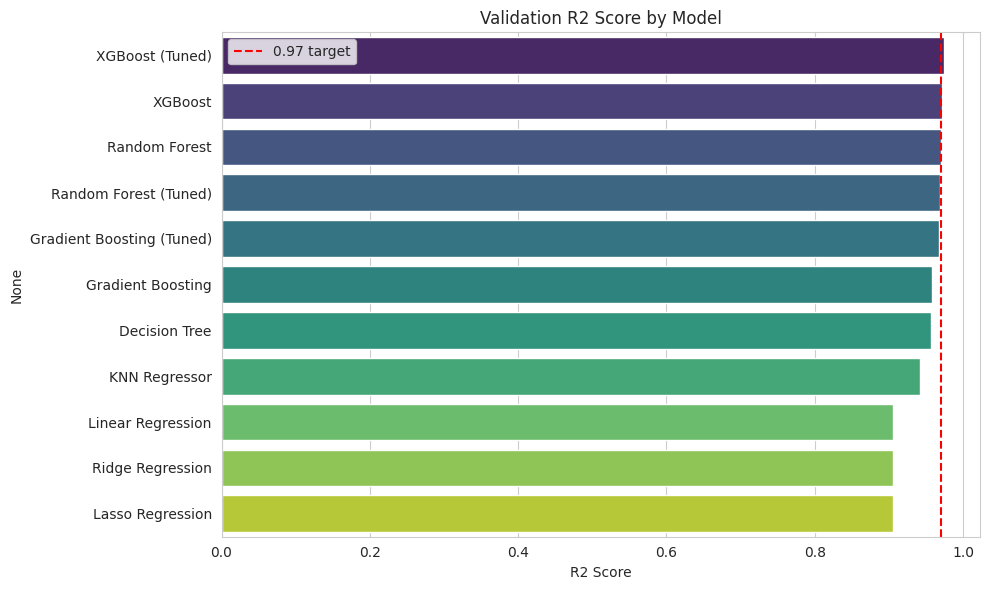

In [30]:
plt.figure(figsize=(10, 6))
sns.barplot(x=results_df['R2'], y=results_df.index, palette='viridis')
plt.title('Validation R2 Score by Model')
plt.xlabel('R2 Score')
plt.axvline(0.97, color='red', linestyle='--', label='0.97 target')
plt.legend()
plt.tight_layout()
plt.show()


In [31]:
best_model_name = results_df['R2'].idxmax()
best_pipeline = fitted_pipelines[best_model_name]
print(f'Best model: {best_model_name}  (Validation R2 = {results_df.loc[best_model_name, "R2"]:.4f})')


Best model: XGBoost (Tuned)  (Validation R2 = 0.9741)


## 13. Submission File


In [32]:
# Retrain the best pipeline on the FULL training data (train + validation) for the final submission
best_pipeline.fit(X, y)

test_preds = best_pipeline.predict(X_test_final)
test_preds = np.clip(test_preds, a_min=0, a_max=None)  # prices can't be negative

submission = pd.DataFrame({'id': test['id'], 'price': test_preds})
submission.to_csv('submission.csv', index=False)
submission.head()


,id,price
0,0,3912.523682
1,1,10396.058594
2,2,4998.029785
3,3,56532.988281
4,4,47131.054688
